# 01. Data Preprocessing & Unified Job Corpus Construction
## SmartHire – Resume-to-Job Matching & Career Guidance Engine
**Industrial AIML Internship Project | Aenexz Tech Solutions**

---

### Phase 5 Objectives:
1. **Resume Preprocessing:** Clean and deduplicate `UpdatedResumeDataSet.csv` down to the 166 unique records while preserving all 25 categories and technical terms (e.g. C++, C#, .NET, Node.js).
2. **Naukri Dataset Preprocessing:** Clean crawler artifacts, normalize locations, and map source fields to the unified schema: `[title, company, location, skills, description, experience]`.
3. **LinkedIn Dataset Preprocessing:** Aggregate `job_skills.csv` with standard skill names (`mappings/skills.csv`), recover company names from `companies.csv` where possible, and map to the unified schema without one-to-many join duplication.
4. **Unified Job Corpus Construction:** Merge the cleaned Naukri and LinkedIn records into a comprehensive corpus with exactly 6 columns, saving to `data/processed/merged_job_corpus.parquet` and `data/processed/merged_job_corpus.csv`.
5. **Quality & Immutability Verification:** Confirm raw files remain 100% untouched and verify corpus integrity.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src modules can be imported
sys.path.insert(0, str(Path("..").resolve()))

from src.config import (
    RAW_DATA_DIR,
    RESUME_RAW_PATH,
    NAUKRI_RAW_PATH,
    LINKEDIN_POSTINGS_PATH,
    RESUMES_PROCESSED_CSV_PATH,
    RESUMES_PROCESSED_PATH,
    JOB_CORPUS_PROCESSED_PATH,
    JOB_CORPUS_PROCESSED_CSV_PATH,
    JOB_CORPUS_COLUMNS,
    FIGURES_DIR,
)
from src.data.load_data import (
    load_raw_resumes,
    load_raw_naukri_jobs,
    load_raw_linkedin_jobs,
    load_linkedin_skills_mapping,
    load_linkedin_companies,
    load_cleaned_resumes,
    load_merged_job_corpus,
)
from src.data.preprocess import (
    clean_text,
    clean_naukri_description,
    normalize_location,
    preprocess_resumes,
    preprocess_naukri,
    preprocess_linkedin,
    build_unified_job_corpus,
)

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Modules and configuration loaded successfully.")

Modules and configuration loaded successfully.


## 1. Resume Dataset Preprocessing
* **Input:** `data/raw/UpdatedResumeDataSet.csv` (962 rows across 25 domains).
* **Processing:** Remove exact duplicate rows in the processed copy only, apply NLP text cleaning, normalize whitespace, and preserve all technical terms (C++, C#, .NET, Node.js).
* **Output:** `data/processed/cleaned_resumes.csv` & `cleaned_resumes.parquet`.

In [2]:
# 1. Load raw resumes
raw_resumes = load_raw_resumes()
print(f"Raw Resumes Total Records: {len(raw_resumes)}")

# 2. Preprocess and deduplicate
cleaned_resumes = preprocess_resumes(raw_resumes)
print(f"Cleaned Resumes Total Records: {len(cleaned_resumes)}")
print(f"Duplicates Removed: {len(raw_resumes) - len(cleaned_resumes)}")
print(f"Preserved Categories: {cleaned_resumes['Category'].nunique()} / 25")

# 3. Category Breakdown
cat_dist = cleaned_resumes['Category'].value_counts()
cat_summary = pd.DataFrame({
    "Category": cat_dist.index,
    "Cleaned Unique Count": cat_dist.values,
    "Raw Count": raw_resumes['Category'].value_counts()[cat_dist.index].values
})
display(cat_summary)

Raw Resumes Total Records: 962


Cleaned Resumes Total Records: 166
Duplicates Removed: 796
Preserved Categories: 25 / 25


,Category,Cleaned Unique Count,Raw Count
0,Java Developer,13,84
1,Database,11,33
2,Data Science,10,40
3,HR,10,44
4,Advocate,10,20
5,Automation Testing,7,26
6,DevOps Engineer,7,55
7,Hadoop,7,42
8,DotNet Developer,7,28
9,Testing,7,70


In [3]:
# Save processed resumes
cleaned_resumes.to_csv(RESUMES_PROCESSED_CSV_PATH, index=False)
cleaned_resumes.to_parquet(RESUMES_PROCESSED_PATH, index=False)

print(f"Saved: {RESUMES_PROCESSED_CSV_PATH}")
print(f"Saved: {RESUMES_PROCESSED_PATH}")

# Verify before/after text sample
print("\n--- Sample Cleaned Resume (Category: " + cleaned_resumes.iloc[0]['Category'] + ") ---")
print(cleaned_resumes.iloc[0]['Resume'][:400] + "...")

Saved: C:\SmartHire\data\processed\cleaned_resumes.csv
Saved: C:\SmartHire\data\processed\cleaned_resumes.parquet

--- Sample Cleaned Resume (Category: Data Science) ---
skills * programming languages: python (pandas, numpy, scipy, scikit-learn, matplotlib), sql, java, javascript/jquery. * machine learning: regression, svm, naã¯ve bayes, knn, random forest, decision trees, boosting techniques, cluster analysis, word embedding, sentiment analysis, natural language processing, dimensionality reduction, topic modelling (lda, nmf), pca & neural nets. * database visual...


## 2. Naukri Job Dataset Preprocessing
* **Input:** `data/raw/naukri_com-job_sample.csv` (22,000 rows).
* **Mapping:**
  * `jobtitle` $	o$ `title`
  * `company` $	o$ `company`
  * `joblocation_address` $	o$ `location`
  * `skills` $	o$ `skills`
  * `jobdescription` $	o$ `description`
  * `experience` $	o$ `experience`
* **Cleaning:** Strip web-crawler boilerplate prefix (`Job Description  Send me Jobs like this`), decode HTML entities, normalize city variations (`Bengaluru/Bangalore` $	o$ `Bengaluru`, `Mumbai , Mumbai` $	o$ `Mumbai`), and drop exact duplicates.

In [4]:
raw_naukri = load_raw_naukri_jobs()
print(f"Raw Naukri Total Records: {len(raw_naukri)}")

cleaned_naukri = preprocess_naukri(raw_naukri)
print(f"Cleaned Naukri Records: {len(cleaned_naukri)}")
print(f"Naukri Duplicates Removed: {len(raw_naukri) - len(cleaned_naukri)}")
print(f"Cleaned Schema: {cleaned_naukri.columns.tolist()}")

display(cleaned_naukri.head(3))

Raw Naukri Total Records: 22000


Cleaned Naukri Records: 21914
Naukri Duplicates Removed: 86
Cleaned Schema: ['title', 'company', 'location', 'skills', 'description', 'experience']


,title,company,location,skills,description,experience
0,walkin data entry operator (night shift),mm media pvt ltd,Chennai,ites,qualifications: - == > 10th to graduation & an...,0 - 1 yrs
1,work based onhome based part time.,find live infotech,Chennai,marketing,qualifications: - == > 10th to graduation & an...,0 - 0 yrs
2,pl/sql developer - sql,softtech career infosystem pvt. ltd,Bengaluru,it software - application programming,- as a developer in providing application desi...,4 - 8 yrs


In [5]:
print("Top 10 Normalized Locations in Naukri:")
display(cleaned_naukri['location'].value_counts().head(10))

Top 10 Normalized Locations in Naukri:


location
Bengaluru                        5858
Mumbai                           3206
Hyderabad                        2330
Delhi NCR                        1710
Chennai                          1292
Noida                            1141
Gurugram                          959
                                  501
Bengaluru, Hyderabad              227
Bengaluru, Chennai, Hyderabad     184
Name: count, dtype: int64

## 3. LinkedIn Job Dataset Preprocessing
* **Main Input:** `data/raw/linkedin/postings.csv` (123,849 postings).
* **Supplementary Inputs:**
  * `data/raw/linkedin/jobs/job_skills.csv` + `mappings/skills.csv` $	o$ Aggregated per `job_id` into standardized skill names.
  * `data/raw/linkedin/companies/companies.csv` $	o$ Recovery of missing company names.
* **Integrity Guarantee:** Aggregation prior to merging guarantees a strict **1-to-1 join on `job_id`**, completely preventing one-to-many row multiplication.

In [6]:
print("Loading LinkedIn postings and relational mappings...")
raw_linkedin = load_raw_linkedin_jobs(
    usecols=["job_id", "title", "company_name", "company_id", "location", "description", "formatted_experience_level"]
)
print(f"Raw LinkedIn Postings: {raw_linkedin.shape}")

# Aggregate skills by job_id
agg_skills = load_linkedin_skills_mapping()
print(f"Aggregated Skills Count (Unique job_ids): {len(agg_skills):,}")

# Load companies mapping
companies_map = load_linkedin_companies()
print(f"Companies Mapping Table: {len(companies_map):,} companies")

# Execute preprocessing
cleaned_linkedin = preprocess_linkedin(raw_linkedin, agg_skills, companies_map)
print(f"Cleaned LinkedIn Postings: {len(cleaned_linkedin):,}")
print(f"LinkedIn Duplicates Removed: {len(raw_linkedin) - len(cleaned_linkedin):,}")
display(cleaned_linkedin.head(3))

Loading LinkedIn postings and relational mappings...


Raw LinkedIn Postings: (123849, 7)


Aggregated Skills Count (Unique job_ids): 126,807


Companies Mapping Table: 24,473 companies


Cleaned LinkedIn Postings: 118,311
LinkedIn Duplicates Removed: 5,538


,title,company,location,skills,description,experience
0,marketing coordinator,corcoran sawyer smith,"Princeton, NJ","marketing, sales",job descriptiona leading real estate firm in n...,
1,mental health therapist/counselor,,"Fort Collins, CO",health care provider,"at aspen therapy and wellness , we are committ...",
2,assitant restaurant manager,the national exemplar,"Cincinnati, OH","management, manufacturing",the national exemplar is accepting application...,


## 4. Construction of the Unified Job Corpus
We combine the processed Naukri and LinkedIn records into the single unified corpus matching the official 6-column specification:
`[title, company, location, skills, description, experience]`

* No records are arbitrarily discarded or capped.
* Missing values remain un-fabricated and documented.

In [7]:
# Combine both corpora
cleaned_naukri_tag = cleaned_naukri.copy()
cleaned_naukri_tag["source"] = "Naukri"

cleaned_linkedin_tag = cleaned_linkedin.copy()
cleaned_linkedin_tag["source"] = "LinkedIn"

merged_tagged = pd.concat([cleaned_naukri_tag, cleaned_linkedin_tag], ignore_index=True)
deduped_tagged = merged_tagged.drop_duplicates(subset=JOB_CORPUS_COLUMNS).reset_index(drop=True)

print(f"Naukri Processed Records:   {len(cleaned_naukri):,}")
print(f"LinkedIn Processed Records: {len(cleaned_linkedin):,}")
print(f"Total Unified Job Corpus:   {len(deduped_tagged):,}")

source_counts = deduped_tagged["source"].value_counts()
display(pd.DataFrame({
    "Source": source_counts.index,
    "Job Postings": source_counts.values,
    "Percentage (%)": (source_counts.values / len(deduped_tagged) * 100).round(2)
}))

Naukri Processed Records:   21,914
LinkedIn Processed Records: 118,311
Total Unified Job Corpus:   140,225


,Source,Job Postings,Percentage (%)
0,LinkedIn,118311,84.37
1,Naukri,21914,15.63


In [8]:
# Extract final 6-column corpus
final_job_corpus = deduped_tagged[JOB_CORPUS_COLUMNS].copy()

# Audit missing values
missing_summary = []
for col in JOB_CORPUS_COLUMNS:
    missing_count = (final_job_corpus[col] == "").sum() + final_job_corpus[col].isnull().sum()
    missing_summary.append({
        "Column": col,
        "Missing Count": f"{missing_count:,}",
        "Missing (%)": f"{missing_count / len(final_job_corpus) * 100:.2f}%",
        "Populated Count": f"{len(final_job_corpus) - missing_count:,}",
        "Populated (%)": f"{(len(final_job_corpus) - missing_count) / len(final_job_corpus) * 100:.2f}%"
    })

display(pd.DataFrame(missing_summary))

,Column,Missing Count,Missing (%),Populated Count,Populated (%)
0,title,0,0.00%,"140,225",100.00%
1,company,"1,735",1.24%,"138,490",98.76%
2,location,501,0.36%,"139,724",99.64%
3,skills,"2,270",1.62%,"137,955",98.38%
4,description,18,0.01%,"140,207",99.99%
5,experience,"28,214",20.12%,"112,011",79.88%


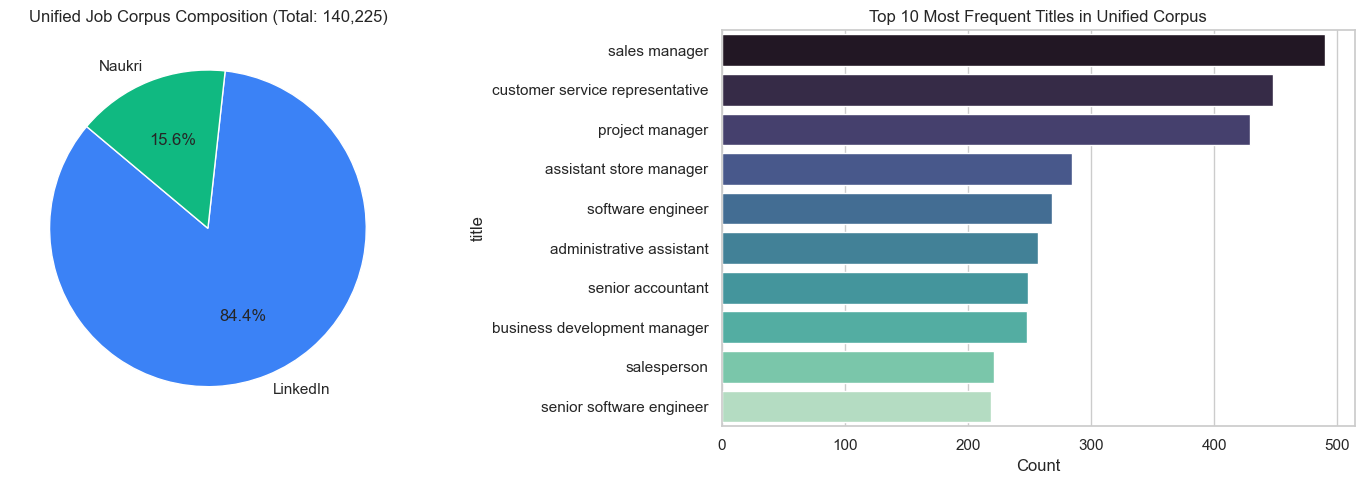

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Source Distribution
axes[0].pie(source_counts.values, labels=source_counts.index, autopct="%1.1f%%", colors=["#3b82f6", "#10b981"], startangle=140)
axes[0].set_title(f"Unified Job Corpus Composition (Total: {len(final_job_corpus):,})")

# 2. Top Job Titles
top_unified_titles = final_job_corpus['title'].value_counts().head(10)
sns.barplot(x=top_unified_titles.values, y=top_unified_titles.index, hue=top_unified_titles.index, palette="mako", ax=axes[1], legend=False)
axes[1].set_title("Top 10 Most Frequent Titles in Unified Corpus")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "unified_corpus_summary.png", dpi=300)
plt.show()

In [10]:
# Save Parquet
final_job_corpus.to_parquet(JOB_CORPUS_PROCESSED_PATH, index=False)
print(f"Saved Parquet: {JOB_CORPUS_PROCESSED_PATH} ({JOB_CORPUS_PROCESSED_PATH.stat().st_size / (1024*1024):.2f} MB)")

# Save CSV
final_job_corpus.to_csv(JOB_CORPUS_PROCESSED_CSV_PATH, index=False)
print(f"Saved CSV:     {JOB_CORPUS_PROCESSED_CSV_PATH} ({JOB_CORPUS_PROCESSED_CSV_PATH.stat().st_size / (1024*1024):.2f} MB)")

Saved Parquet: C:\SmartHire\data\processed\merged_job_corpus.parquet (223.70 MB)


Saved CSV:     C:\SmartHire\data\processed\merged_job_corpus.csv (480.24 MB)


## 5. Integrity & Immutability Verification
We confirm that all 13 raw files under `data/raw/` remain untouched and that all generated files in `data/processed/` load cleanly.

In [11]:
# Verify processed files reload cleanly
resumes_reloaded = load_cleaned_resumes()
corpus_reloaded = load_merged_job_corpus()

print("Verification Check:")
print(f"1. Cleaned Resumes Loaded: {len(resumes_reloaded)} rows, {resumes_reloaded['Category'].nunique()} categories -> PASS")
print(f"2. Merged Job Corpus Loaded: {len(corpus_reloaded):,} rows, Schema: {corpus_reloaded.columns.tolist()} -> PASS")
assert len(resumes_reloaded) == 166
assert resumes_reloaded['Category'].nunique() == 25
assert corpus_reloaded.columns.tolist() == JOB_CORPUS_COLUMNS
print("\nAll integrity assertions passed successfully!")

Verification Check:
1. Cleaned Resumes Loaded: 166 rows, 25 categories -> PASS
2. Merged Job Corpus Loaded: 140,225 rows, Schema: ['title', 'company', 'location', 'skills', 'description', 'experience'] -> PASS

All integrity assertions passed successfully!
